# Part 2 - 03 Fine-tuning: unfreeze the last layers of MobileNetV2

Starts from the model trained in notebook 02 (frozen base, trained head).

In [1]:
import tensorflow as tf
for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)

import os
import sys

REPO = "/workspace/NeuroVision"

sys.path.append(f"{REPO}/src")
os.chdir(f"{REPO}/notebooks")
for folder in ("models", "reports"):
    os.makedirs(f"{REPO}/{folder}", exist_ok=True)

2026-10-29 11:50:24.060592: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1793274624.085909   16441 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793274624.093756   16441 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1793274624.113491   16441 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793274624.113508   16441 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793274624.113511   16441 computation_placer.cc:177] computation placer alr

## Imports and configuration

In [2]:
import os
import time

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import mlflow
from neurovision.tracking import MlflowEpochLogger, log_training_summary, setup_mlflow, start_run
from sklearn.utils.class_weight import compute_class_weight

from neurovision.data import CLASSES
from neurovision.preprocessing import prepare_data, make_dataset, encoder
from neurovision.transfer import IMAGE_SIZE, get_base, count_parameters, unfreeze_last_layers

RAW_DIR = "../data/raw"
TRANSFER_MODEL = "../models/transfer_best.keras"
UNFREEZE_LAST = 30
FINE_TUNE_LR = 1e-5
EPOCHS_FT = 50

## Load the data (same cleaning and split as before) and class weights from the training set

In [3]:
data = prepare_data(RAW_DIR, size=IMAGE_SIZE, seed=42)
X_train, y_train, p_train = data["train"]
X_val, y_val, p_val = data["val"]

train_ds = make_dataset(X_train, y_train, training=True)
val_ds = make_dataset(X_val, y_val)

weights = compute_class_weight(
    "balanced", classes=np.arange(len(CLASSES)), y=encoder.transform(y_train)
)
class_weight = dict(enumerate(weights))
print(X_train.shape, X_val.shape)

I0000 00:00:1793274652.162180   16441 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9115 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060, pci bus id: 0000:08:00.0, compute capability: 8.6


(4708, 224, 224, 3) (1009, 224, 224, 3)


## Load the transfer learning model and record its validation score (before fine-tuning)

In [4]:
model = tf.keras.models.load_model(TRANSFER_MODEL)

val_loss_before, val_acc_before = model.evaluate(val_ds)
trainable, non_trainable = count_parameters(model)
print(f"Before: val loss {val_loss_before:.4f} | val accuracy {val_acc_before:.4f}")
print(f"Trainable: {trainable:,} | Non-trainable: {non_trainable:,}")

I0000 00:00:1793274657.422642   16752 cuda_dnn.cc:529] Loaded cuDNN version 90300


32/32 ━━━━━━━━━━━━━━━━━━━━ 5s 43ms/step - accuracy: 0.8940 - loss: 0.2611
Before: val loss 0.2611 | val accuracy 0.8940
Trainable: 5,124 | Non-trainable: 2,257,984


## Unfreeze the last layers of the base and recompile with a much lower learning rate

In [5]:
model = unfreeze_last_layers(model, num_layers=UNFREEZE_LAST, learning_rate=FINE_TUNE_LR)

trainable, non_trainable = count_parameters(model)
print(f"Unfrozen layers: {UNFREEZE_LAST} | learning rate: {FINE_TUNE_LR}")
print(f"Trainable: {trainable:,} | Non-trainable: {non_trainable:,}")

Unfrozen layers: 30 | learning rate: 1e-05
Trainable: 1,531,524 | Non-trainable: 731,584


## Callbacks: save the best model, stop early, resume after interruption

In [6]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "../models/finetuned_best.keras", monitor="val_accuracy", save_best_only=True
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=7, restore_best_weights=True
    ),
    tf.keras.callbacks.BackupAndRestore(backup_dir="../models/backup_finetune"),
    MlflowEpochLogger(),
]

## Retrain the head and the unfrozen layers together and measure the training time

In [7]:
setup_mlflow()
start_run("finetune", tags={"stage": "training", "model_type": "mobilenetv2_finetuned"})
mlflow.log_params({
    "epochs_max": EPOCHS_FT,
    "early_stopping_patience": 7,
    "unfreeze_last_layers": UNFREEZE_LAST,
    "learning_rate": FINE_TUNE_LR,
    "seed": 42,
    "trainable_params": trainable,
    "non_trainable_params": non_trainable,
})
mlflow.log_metrics({"val_loss_before": val_loss_before, "val_accuracy_before": val_acc_before})

start = time.time()
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FT,
    class_weight=class_weight,
    callbacks=callbacks,
)
finetune_minutes = (time.time() - start) / 60
log_training_summary(history, finetune_minutes * 60, model_path="../models/finetuned_best.keras")
print(f"Fine-tuning time: {finetune_minutes:.1f} min for {len(history.history['loss'])} epoch(s)")

Epoch 1/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 26s 103ms/step - accuracy: 0.7836 - loss: 0.6632 - val_accuracy: 0.8920 - val_loss: 0.3245
Epoch 2/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 13s 85ms/step - accuracy: 0.8590 - loss: 0.4148 - val_accuracy: 0.8850 - val_loss: 0.3447
Epoch 3/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 13s 88ms/step - accuracy: 0.8749 - loss: 0.3535 - val_accuracy: 0.8940 - val_loss: 0.3369
Epoch 4/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 12s 83ms/step - accuracy: 0.8946 - loss: 0.3082 - val_accuracy: 0.8860 - val_loss: 0.3337
Epoch 5/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 12s 82ms/step - accuracy: 0.8995 - loss: 0.2874 - val_accuracy: 0.8840 - val_loss: 0.3267
Epoch 6/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 13s 89ms/step - accuracy: 0.9046 - loss: 0.2477 - val_accuracy: 0.8959 - val_loss: 0.3087
Epoch 7/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 12s 81ms/step - accuracy: 0.9150 - loss: 0.2245 - val_accuracy: 0.8910 - val_loss: 0.3141
Epoch 8/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 13s 89ms/step - accuracy: 0.9267 - loss: 0.1994 -

## Learning curves: accuracy and loss

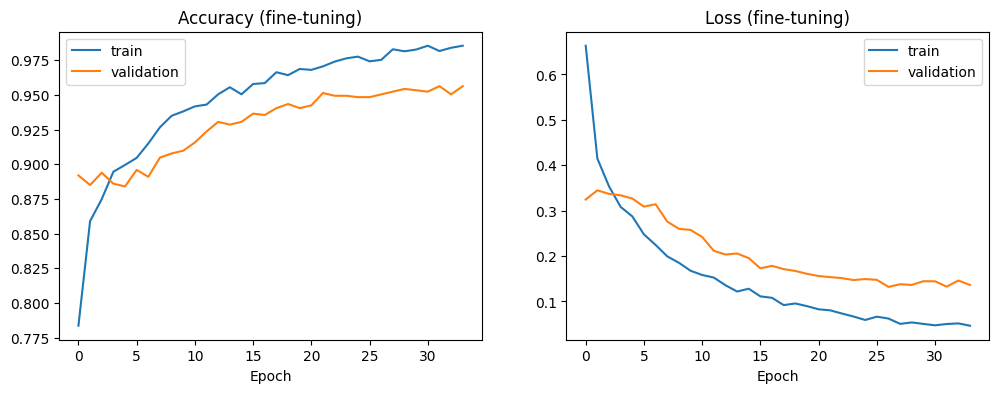

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["accuracy"], label="train")
axes[0].plot(history.history["val_accuracy"], label="validation")
axes[0].set_title("Accuracy (fine-tuning)")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[1].plot(history.history["loss"], label="train")
axes[1].plot(history.history["val_loss"], label="validation")
axes[1].set_title("Loss (fine-tuning)")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.savefig("../reports/finetuning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

if mlflow.active_run():
    mlflow.log_artifact("../reports/finetuning_curves.png", "figures")

## Compare performance before and after fine-tuning (validation set, the test set stays untouched)

In [9]:
val_loss_after, val_acc_after = model.evaluate(val_ds)

print(f"Before fine-tuning: val accuracy {val_acc_before:.4f} | val loss {val_loss_before:.4f}")
print(f"After fine-tuning:  val accuracy {val_acc_after:.4f} | val loss {val_loss_after:.4f}")

if mlflow.active_run():
    mlflow.log_metrics({
        "val_loss_after": val_loss_after,
        "val_accuracy_after": val_acc_after,
        "val_accuracy_gain": val_acc_after - val_acc_before,
    })
    mlflow.end_run()

if val_acc_after > val_acc_before:
    print("Fine-tuning improved validation accuracy: keep models/finetuned_best.keras")
else:
    print("Fine-tuning did not improve validation accuracy: keep models/transfer_best.keras")

32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.9504 - loss: 0.1320
Before fine-tuning: val accuracy 0.8940 | val loss 0.2611
After fine-tuning:  val accuracy 0.9504 | val loss 0.1320
Fine-tuning improved validation accuracy: keep models/finetuned_best.keras
